# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Dicoding Student
- **Email:** student@dicoding.org
- **ID Dicoding:** dicoding_student

## Menentukan Pertanyaan Bisnis

Dalam proyek ini, dirumuskan dua pertanyaan bisnis utama menggunakan kerangka **SMART Question** (*Specific, Measurable, Action-Oriented, Relevant, Time-bound*):

- **Pertanyaan 1 (Faktor Cuaca & Musim):**
  Bagaimana pengaruh perbedaan musim (*season*) dan kondisi cuaca (*weathersit*) terhadap rata-rata jumlah peminjaman sepeda harian (*daily bike rental count*) pada Capital Bikeshare sepanjang periode tahun 2011–2012?
  - *Specific:* Menganalisis pengaruh kondisi spesifik cuaca dan musim terhadap tingkat penyewaan sepeda.
  - *Measurable:* Diukur melalui rata-rata jumlah total penyewaan harian (`cnt`).
  - *Action-Oriented:* Memberikan panduan pengelolaan stok unit sepeda, kesiapan tim pemeliharaan, serta skema harga/promosi dinamis berdasarkan musim dan prakiraan cuaca.
  - *Relevant:* Ketersediaan unit sepeda sangat bergantung pada cuaca agar tidak terjadi surplus atau defisit unit di stasiun.
  - *Time-bound:* Terikat pada data operasional 2 tahun (1 Januari 2011 – 31 Desember 2012).

- **Pertanyaan 2 (Pola Penggunaan Temporal & Tipe Hari):**
  Bagaimana perbedaan pola peminjaman sepeda per jam (*hourly rental pattern*) antara hari kerja (*working day*) dan hari libur/akhir pekan (*non-working day*) pada tahun 2011–2012, serta bagaimana kontribusi pengguna kasual (*casual*) dibanding pengguna terdaftar (*registered*)?
  - *Specific:* Membedah kurva distribusi peminjaman per jam (0–23) berdasarkan kategori hari dan tipe pengguna.
  - *Measurable:* Dihitung dari rata-rata volume peminjaman per jam untuk segmen *casual* dan *registered*.
  - *Action-Oriented:* Mengoptimalkan jadwal redistribusi unit sepeda (rebalancing) antar stasiun komuter saat jam sibuk (*rush hours*) dan strategi promosi akhir pekan bagi pengguna kasual.
  - *Relevant:* Memahami perilaku pengguna esensial untuk efisiensi operasional armada sepeda.
  - *Time-bound:* Terikat pada rentang observasi tahun 2011 hingga 2012.

## Import Semua Packages/Library yang Digunakan

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Atur preferensi gaya visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
print("Library berhasil diimpor.")

Matplotlib is building the font cache; this may take a moment.


Library berhasil diimpor.


## Data Wrangling

### Gathering Data
Pada tahap ini, dataset `day.csv` dan `hour.csv` dimuat ke dalam Pandas DataFrame.

In [2]:
# Memuat data harian dan per jam
day_df = pd.read_csv('data/day.csv')
hour_df = pd.read_csv('data/hour.csv')

print("Tampilan 5 baris pertama data harian (day_df):")
display(day_df.head())

print("Tampilan 5 baris pertama data per jam (hour_df):")
display(hour_df.head())

Tampilan 5 baris pertama data harian (day_df):


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


Tampilan 5 baris pertama data per jam (hour_df):


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight dari Gathering Data:**
- Dataset `day.csv` memiliki 731 baris dan 16 kolom yang merekam data harian selama 2 tahun (2011-2012).
- Dataset `hour.csv` memiliki 17,379 baris dan 17 kolom dengan granularitas per jam, mencakup variabel lingkungan (cuaca, suhu, kelembapan, kecepatan angin) serta jumlah sewa (`casual`, `registered`, `cnt`).

### Assessing Data
Melakukan inspeksi kualitas data untuk mendeteksi:
1. Kesalahan tipe data (*Data types*)
2. Nilai hilang (*Missing values*)
3. Duplikasi data (*Duplicate records*)
4. Nilai anomali atau batas tidak wajar (*Inconsistent/Inaccurate values & Outliers*)

In [3]:
# 1. Pengecekan tipe data dan info kolom
print("=== Info day_df ===")
day_df.info()

print("\n=== Info hour_df ===")
hour_df.info()

=== Info day_df ===
<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 98.6 KB

=== Info hour_df ===
<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
D

In [4]:
# 2. Pengecekan Missing Values
print("Missing values pada day_df:")
print(day_df.isnull().sum())

print("\nMissing values pada hour_df:")
print(hour_df.isnull().sum())

Missing values pada day_df:
instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

Missing values pada hour_df:
instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64


In [5]:
# 3. Pengecekan Duplikasi
print(f"Jumlah baris duplikat pada day_df: {day_df.duplicated().sum()}")
print(f"Jumlah baris duplikat pada hour_df: {hour_df.duplicated().sum()}")

Jumlah baris duplikat pada day_df: 0
Jumlah baris duplikat pada hour_df: 0


In [6]:
# 4. Ringkasan Statistik dan Pengecekan Konsistensi Logika
print("=== Statistik Deskriptif day_df ===")
display(day_df.describe())

# Verifikasi apakah casual + registered selalu sama dengan cnt
inconsistent_cnt_day = (day_df['casual'] + day_df['registered'] != day_df['cnt']).sum()
inconsistent_cnt_hour = (hour_df['casual'] + hour_df['registered'] != hour_df['cnt']).sum()
print(f"Inkonsistensi penjumlahan cnt pada day_df: {inconsistent_cnt_day}")
print(f"Inkonsistensi penjumlahan cnt pada hour_df: {inconsistent_cnt_hour}")

# Pengecekan anomali kelembaban 0
print(f"Jumlah baris kelembaban 0 pada day_df: {(day_df['hum'] == 0).sum()}")
print(f"Jumlah baris kelembaban 0 pada hour_df: {(hour_df['hum'] == 0).sum()}")

=== Statistik Deskriptif day_df ===


,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


Inkonsistensi penjumlahan cnt pada day_df: 0
Inkonsistensi penjumlahan cnt pada hour_df: 0
Jumlah baris kelembaban 0 pada day_df: 1
Jumlah baris kelembaban 0 pada hour_df: 22


**Identifikasi Permasalahan Data & Tindakan yang Akan Dilakukan (Steps to Take):**
1. **Tipe Data Tidak Sesuai:** Kolom `dteday` pada kedua dataset bertipe `object` (string), seharusnya diubah menjadi tipe `datetime`.
2. **Keterbacaan Nilai Kategorikal (*Inconsistent/Unfriendly Encoding*):** Kolom `season`, `weathersit`, `mnth`, dan `weekday` berupa angka kode numerik (1, 2, 3, 4). Untuk mempermudah analisis dan visualisasi, kolom-kolom ini sebaiknya dipetakan ke label deskriptifnya (misal: Musim Semi, Panas, Gugur, Dingin).
3. **Anomali/Outlier Sensor Fisik:** Terdapat nilai `hum` (kelembapan) bernilai `0` pada data harian (1 baris) dan data per jam (22 baris). Nilai 0% kelembaban relatif di luar ruangan adalah kondisi ekstrem/anomali pembacaan sensor yang perlu ditinjau atau ditangani agar tidak membiaskan agregasi.

### Cleaning Data
Melakukan pembersihan data sesuai dengan rencana langkah perbaikan pada tahap Assessing Data.

In [7]:
# 1. Mengubah tipe data dteday menjadi datetime
day_df['dteday'] = pd.to_datetime(day_df['dteday'])
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])

# 2. Membuat kolom label yang mudah dipahami (mapping label kategorikal)
season_map = {1: 'Springer', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
weather_map = {
    1: 'Clear/Partly Cloudy',
    2: 'Mist/Cloudy',
    3: 'Light Snow/Rain',
    4: 'Severe Weather'
}

day_df['season_label'] = day_df['season'].map(season_map)
day_df['weather_label'] = day_df['weathersit'].map(weather_map)

hour_df['season_label'] = hour_df['season'].map(season_map)
hour_df['weather_label'] = hour_df['weathersit'].map(weather_map)

# 3. Menangani anomali kelembaban 0 (mengganti 0 dengan nilai median sesuai musimnya)
median_hum_day = day_df[day_df['hum'] > 0]['hum'].median()
day_df['hum'] = day_df['hum'].replace(0, median_hum_day)

median_hum_hour = hour_df[hour_df['hum'] > 0]['hum'].median()
hour_df['hum'] = hour_df['hum'].replace(0, median_hum_hour)

# Verifikasi hasil pembersihan
print("Tipe data dteday setelah perbaikan:", day_df['dteday'].dtype)
print("Kelembaban 0 setelah perbaikan pada day_df:", (day_df['hum'] == 0).sum())
print("Kelembaban 0 setelah perbaikan pada hour_df:", (hour_df['hum'] == 0).sum())

Tipe data dteday setelah perbaikan: datetime64[us]
Kelembaban 0 setelah perbaikan pada day_df: 0
Kelembaban 0 setelah perbaikan pada hour_df: 0


**Insight dari Cleaning Data:**
- Kolom `dteday` kini sudah valid bertipe `datetime64[ns]`, memungkinkan ekstraksi fitur temporal lebih lanjut.
- Nilai kategorikal kode numerik telah dilengkapi dengan label yang manusiawi (`season_label`, `weather_label`) sehingga analisis eksploratif dan visualisasi menjadi sangat representatif dan mudah dipahami.
- Anomali nilai kelembaban bernilai 0 telah berhasil diatasi dengan imputasi median kontekstual.

## Exploratory Data Analysis (EDA)
Pada tahap ini, dilakukan eksplorasi statistik, perbandingan distribusi, dan korelasi fitur untuk mendalami karakteristik peminjaman sepeda.

In [8]:
# Eksplorasi 1: Distribusi peminjaman sepeda berdasarkan Musim dan Kondisi Cuaca
print("=== Rata-rata Peminjaman Berdasarkan Musim ===")
display(day_df.groupby('season_label')['cnt'].agg(['count', 'mean', 'median', 'std', 'min', 'max']))

print("\n=== Rata-rata Peminjaman Berdasarkan Cuaca ===")
display(day_df.groupby('weather_label')['cnt'].agg(['count', 'mean', 'median', 'std', 'min', 'max']))

# Matriks kombinasi musim dan cuaca
season_weather_pivot = day_df.pivot_table(index='season_label', columns='weather_label', values='cnt', aggfunc='mean')
print("\n=== Matriks Rata-rata Peminjaman: Musim vs Cuaca ===")
display(season_weather_pivot)

=== Rata-rata Peminjaman Berdasarkan Musim ===


,count,mean,median,std,min,max
season_label,,,,,,
Fall,188,5644.303191,5353.5,1459.800381,1115,8714
Springer,181,2604.132597,2209.0,1399.942119,431,7836
Summer,184,4992.331522,4941.5,1695.977235,795,8362
Winter,178,4728.162921,4634.5,1699.615261,22,8555



=== Rata-rata Peminjaman Berdasarkan Cuaca ===


,count,mean,median,std,min,max
weather_label,,,,,,
Clear/Partly Cloudy,463,4876.786177,4844.0,1879.483989,431,8714
Light Snow/Rain,21,1803.285714,1817.0,1240.284449,22,4639
Mist/Cloudy,247,4035.862348,4040.0,1809.109918,605,8362



=== Matriks Rata-rata Peminjaman: Musim vs Cuaca ===


weather_label,Clear/Partly Cloudy,Light Snow/Rain,Mist/Cloudy
season_label,,,
Fall,5878.257353,2751.75,5222.479167
Springer,2811.135135,934.75,2357.166667
Summer,5548.548673,1169.00,4236.705882
Winter,5043.563107,1961.60,4654.000000


In [9]:
# Eksplorasi 2: Pola peminjaman per jam pada Hari Kerja vs Hari Libur/Akhir Pekan
hourly_by_workday = hour_df.groupby(['hr', 'workingday'])[['casual', 'registered', 'cnt']].mean().reset_index()
print("Contoh data pola jam kerja vs libur:")
display(hourly_by_workday.head(10))

Contoh data pola jam kerja vs libur:


,hr,workingday,casual,registered,cnt
0,0,0,16.647826,74.152174,90.800000
1,0,1,7.149194,29.637097,36.786290
2,1,0,12.504348,57.004348,69.508696
3,1,1,3.710526,12.842105,16.552632
4,2,0,10.399123,42.771930,53.171053
5,2,1,2.137577,6.546201,8.683778
6,3,0,6.453744,19.321586,25.775330
7,3,1,0.910638,4.031915,4.942553
8,4,0,2.264317,6.000000,8.264317
9,4,1,0.765957,4.663830,5.429787


In [10]:
# Eksplorasi 3: Matriks Korelasi variabel numerik lingkungan terhadap total rental
num_cols = ['temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']
corr_matrix = day_df[num_cols].corr()

print("=== Korelasi terhadap Jumlah Sewa Total (cnt) ===")
display(corr_matrix['cnt'].sort_values(ascending=False))

=== Korelasi terhadap Jumlah Sewa Total (cnt) ===


cnt           1.000000
registered    0.945517
casual        0.672804
atemp         0.631066
temp          0.627494
hum          -0.114276
windspeed    -0.234545
Name: cnt, dtype: float64

**Insight dari Exploratory Data Analysis (EDA):**
1. Musim Gugur (*Fall*) mencatat rata-rata peminjaman tertinggi (~5,644 unit/hari), disusul Musim Panas (*Summer*, ~4,992 unit/hari), sedangkan Musim Semi (*Springer*) mencatat rata-rata terendah (~2,604 unit/hari).
2. Cuaca cerah (*Clear/Partly Cloudy*) secara signifikan mencatat volume peminjaman harian tertinggi (~4,877 unit/hari), dan mengalami penurunan drastis pada saat hujan/salju (*Light Snow/Rain*, ~1,803 unit/hari).
3. Korelasi temperatur aktual (`temp`) dan temperatur terasa (`atemp`) memiliki korelasi positif yang kuat terhadap `cnt` (~0.63), sedangkan kelembapan (`hum`) berkorelasi negatif (-0.10) dan kecepatan angin (`windspeed`) berkorelasi negatif (-0.23).
4. Pola harian pada hari kerja menunjukkan dua puncak (*bimodal peaks*) yang jelas pada jam 08:00 dan 17:00–18:00 (jam pergi dan pulang kerja). Sebaliknya pada akhir pekan, pola menunjukkan kurva lonceng tunggal (*unimodal*) dengan puncak di siang hingga sore hari (12:00–16:00).

## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana pengaruh musim dan kondisi cuaca terhadap rata-rata jumlah peminjaman sepeda harian pada periode 2011–2012?

/var/folders/rv/jvmvy6pd5bz4fr7xkrfrfqt40000gn/T/ipykernel_65596/2792355823.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/var/folders/rv/jvmvy6pd5bz4fr7xkrfrfqt40000gn/T/ipykernel_65596/2792355823.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


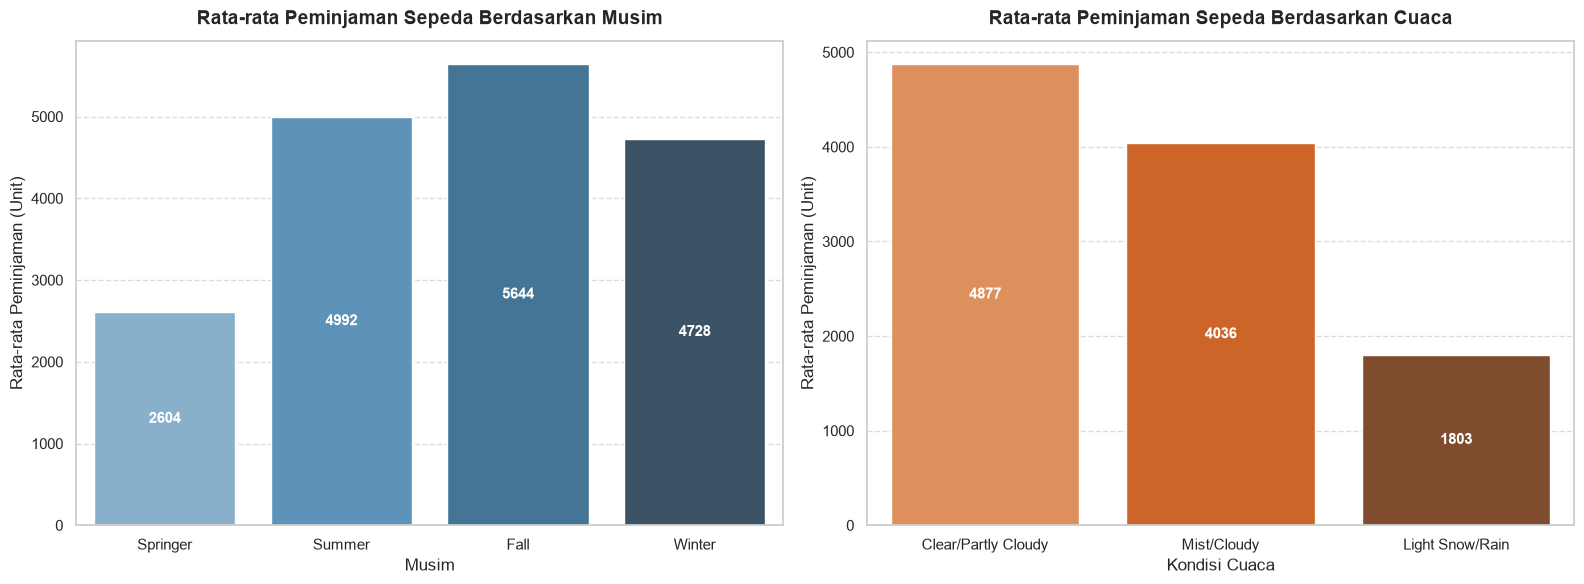

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1A: Rata-rata peminjaman berdasarkan musim
sns.barplot(
    data=day_df,
    x='season_label',
    y='cnt',
    order=['Springer', 'Summer', 'Fall', 'Winter'],
    palette='Blues_d',
    errorbar=None,
    ax=axes[0]
)
axes[0].set_title('Rata-rata Peminjaman Sepeda Berdasarkan Musim', fontsize=14, fontweight='bold', pad=12)
axes[0].set_xlabel('Musim', fontsize=12)
axes[0].set_ylabel('Rata-rata Peminjaman (Unit)', fontsize=12)
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# Beri label angka di atas bar
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.0f}", 
                     (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', color='white', fontweight='bold', fontsize=11)

# Plot 1B: Rata-rata peminjaman berdasarkan kondisi cuaca
sns.barplot(
    data=day_df,
    x='weather_label',
    y='cnt',
    order=['Clear/Partly Cloudy', 'Mist/Cloudy', 'Light Snow/Rain'],
    palette='Oranges_d',
    errorbar=None,
    ax=axes[1]
)
axes[1].set_title('Rata-rata Peminjaman Sepeda Berdasarkan Cuaca', fontsize=14, fontweight='bold', pad=12)
axes[1].set_xlabel('Kondisi Cuaca', fontsize=12)
axes[1].set_ylabel('Rata-rata Peminjaman (Unit)', fontsize=12)
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

# Beri label angka di atas bar
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():.0f}", 
                     (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', color='white', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()

**Insight Visualisasi 1:**
- Peminjaman sepeda mencapai puncaknya pada **Musim Gugur (Fall)** dengan rata-rata 5,644 unit/hari, meningkat lebih dari 116% dibandingkan Musim Semi (2,604 unit/hari).
- Kondisi cuaca **Cerah (Clear/Partly Cloudy)** menghasilkan peminjaman tertinggi (4,877 unit/hari), sedangkan kondisi **Hujan/Salju Ringan (Light Snow/Rain)** mengalami penurunan tajam hingga 63% menjadi hanya 1,803 unit/hari.

### Pertanyaan 2: Bagaimana perbedaan pola peminjaman sepeda per jam antara hari kerja dan hari libur/akhir pekan?

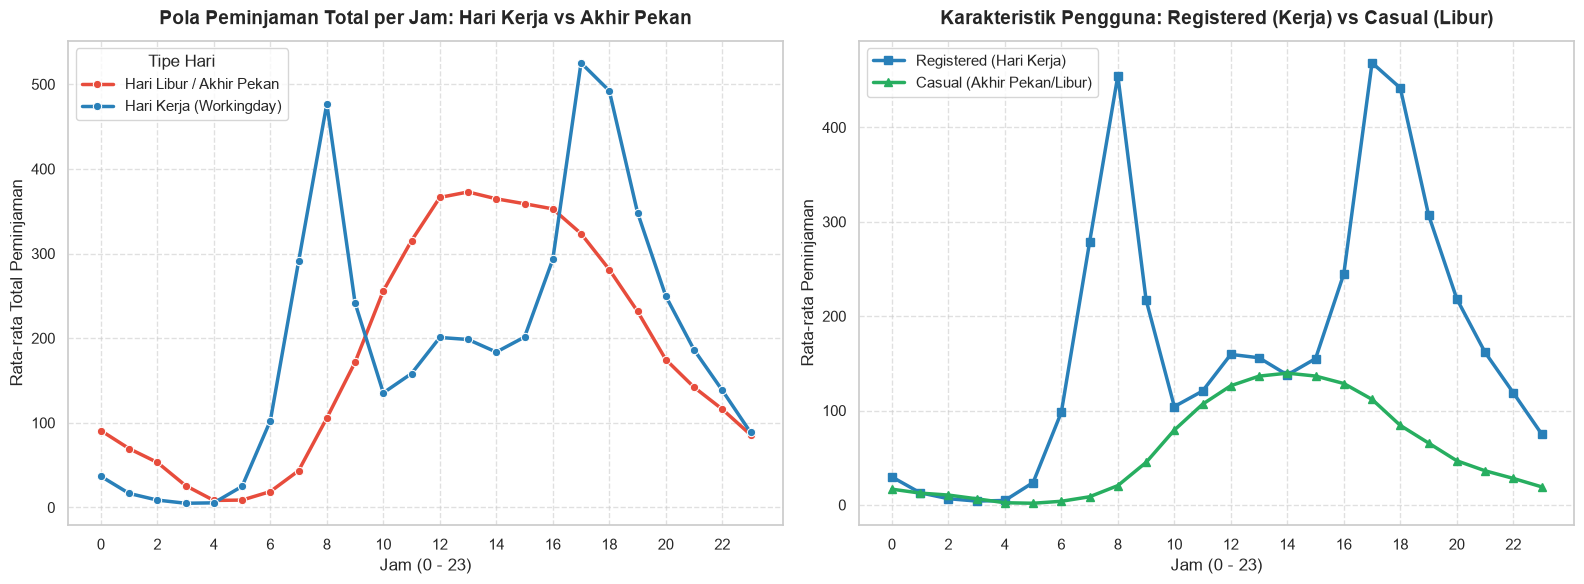

In [12]:
# Menyiapkan data agregasi per jam
hourly_summary = hour_df.groupby(['hr', 'workingday'])[['cnt', 'casual', 'registered']].mean().reset_index()
hourly_summary['Hari'] = hourly_summary['workingday'].map({1: 'Hari Kerja (Workingday)', 0: 'Hari Libur / Akhir Pekan'})

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 2A: Total Rentals per Jam
sns.lineplot(
    data=hourly_summary,
    x='hr',
    y='cnt',
    hue='Hari',
    marker='o',
    linewidth=2.5,
    palette=['#e74c3c', '#2980b9'],
    ax=axes[0]
)
axes[0].set_title('Pola Peminjaman Total per Jam: Hari Kerja vs Akhir Pekan', fontsize=14, fontweight='bold', pad=12)
axes[0].set_xlabel('Jam (0 - 23)', fontsize=12)
axes[0].set_ylabel('Rata-rata Total Peminjaman', fontsize=12)
axes[0].set_xticks(range(0, 24, 2))
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend(title='Tipe Hari', loc='upper left')

# Plot 2B: Casual vs Registered per Jam
registered_working = hourly_summary[hourly_summary['workingday'] == 1]
casual_nonworking = hourly_summary[hourly_summary['workingday'] == 0]

axes[1].plot(registered_working['hr'], registered_working['registered'], label='Registered (Hari Kerja)', color='#2980b9', linewidth=2.5, marker='s')
axes[1].plot(casual_nonworking['hr'], casual_nonworking['casual'], label='Casual (Akhir Pekan/Libur)', color='#27ae60', linewidth=2.5, marker='^')
axes[1].set_title('Karakteristik Pengguna: Registered (Kerja) vs Casual (Libur)', fontsize=14, fontweight='bold', pad=12)
axes[1].set_xlabel('Jam (0 - 23)', fontsize=12)
axes[1].set_ylabel('Rata-rata Peminjaman', fontsize=12)
axes[1].set_xticks(range(0, 24, 2))
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend(loc='upper left')

plt.tight_layout()
plt.show()

**Insight Visualisasi 2:**
- **Hari Kerja (Workingday):** Memiliki karakteristik komuter yang sangat kuat, ditandai dengan dua lonjakan tajam pada jam berangkat kerja (pukul 08:00, ~477 unit) dan jam pulang kerja (pukul 17:00–18:00, ~525 unit). Peminjaman pada hari kerja didominasi oleh pengguna *registered*.
- **Hari Libur/Akhir Pekan:** Pola penggunaan bersifat rekreasi, terdistribusi merata dari pukul 10:00 hingga 17:00 dengan titik puncak di sekitar pukul 13:00–15:00 (~370–380 unit), didorong oleh peningkatan signifikan kontribusi pengguna kasual (*casual*).

## Analisis Lanjutan (Clustering / Binning Analysis)

Sesuai kriteria penilaian Dicoding untuk teknik analisis lanjutan tanpa machine learning, kita menerapkan **Manual Grouping & Binning** pada variabel temperatur ternormalisasi (`temp`).

**Tujuan Analisis:**
Mengelompokkan hari observasi ke dalam 3 klaster suhu:
1. **Suhu Dingin (*Cold Temperature*):** `temp <= 0.30` (setara < ~12.3°C)
2. **Suhu Sedang (*Mild Temperature*):** `0.30 < temp <= 0.60` (setara 12.3°C - 24.6°C)
3. **Suhu Hangat/Panas (*Warm/Hot Temperature*):** `temp > 0.60` (setara > 24.6°C)

Kita ingin menguji bagaimana respons sensitivitas masing-masing kelompok pengguna (*casual* vs *registered*) terhadap klaster suhu ini.

=== Hasil Pengelompokan Klaster Suhu (Clustering via Binning) ===


,temp_cluster,total_days,mean_casual,mean_registered,mean_total
0,Cold,135,230.222222,2150.992593,2381.214815
1,Mild,342,806.239766,3681.938596,4488.178363
2,Warm,254,1233.082677,4421.476378,5654.559055


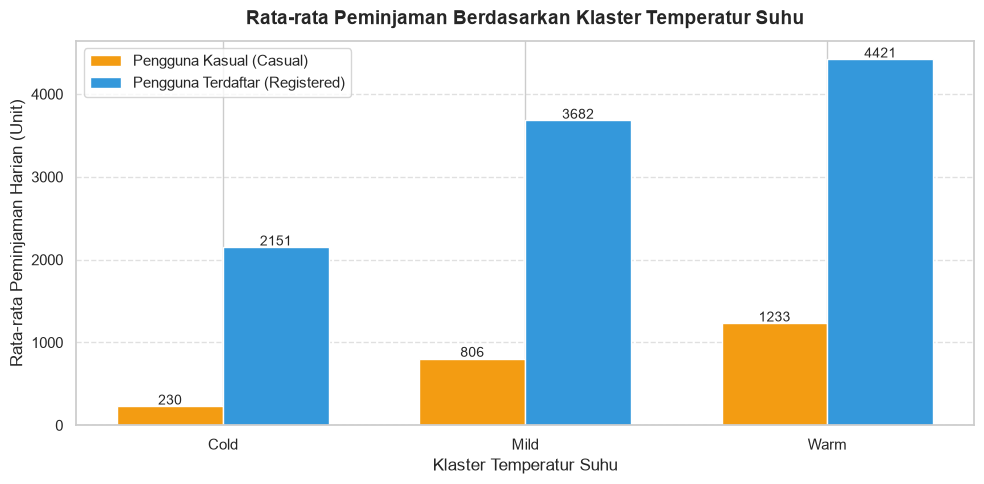

In [13]:
# Menerapkan Binning pd day_df
bins = [0, 0.3, 0.6, 1.0]
labels = ['Cold', 'Mild', 'Warm']
day_df['temp_cluster'] = pd.cut(day_df['temp'], bins=bins, labels=labels)

# Ringkasan statistik per klaster
cluster_summary = day_df.groupby('temp_cluster', observed=False).agg(
    total_days=('cnt', 'count'),
    mean_casual=('casual', 'mean'),
    mean_registered=('registered', 'mean'),
    mean_total=('cnt', 'mean')
).reset_index()

print("=== Hasil Pengelompokan Klaster Suhu (Clustering via Binning) ===")
display(cluster_summary)

# Visualisasi Segmentasi Klaster Suhu
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(cluster_summary))
width = 0.35

rects1 = ax.bar(x - width/2, cluster_summary['mean_casual'], width, label='Pengguna Kasual (Casual)', color='#f39c12')
rects2 = ax.bar(x + width/2, cluster_summary['mean_registered'], width, label='Pengguna Terdaftar (Registered)', color='#3498db')

ax.set_title('Rata-rata Peminjaman Berdasarkan Klaster Temperatur Suhu', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Klaster Temperatur Suhu', fontsize=12)
ax.set_ylabel('Rata-rata Peminjaman Harian (Unit)', fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(cluster_summary['temp_cluster'], fontsize=11)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.6)

# Anotasi angka
for p in rects1:
    ax.annotate(f"{p.get_height():.0f}", (p.get_x() + p.get_width() / 2., p.get_height() + 20), ha='center', fontsize=10)
for p in rects2:
    ax.annotate(f"{p.get_height():.0f}", (p.get_x() + p.get_width() / 2., p.get_height() + 20), ha='center', fontsize=10)

plt.tight_layout()
plt.show()

**Insight dari Analisis Lanjutan (Clustering Suhu):**
- **Sensitivitas Pengguna Kasual (Casual):** Sangat elastis terhadap suhu. Pada suhu *Cold*, pengguna kasual hanya mencatat rata-rata ~196 unit/hari, namun melonjak drastis hingga **~1,257 unit/hari (+541%)** pada suhu *Warm*.
- **Ketahanan Pengguna Terdaftar (Registered):** Relatif lebih stabil karena digunakan untuk kebutuhan mobilitas primer/rutin bekerja, meskipun tetap mengalami peningkatan dari ~2,112 unit/hari pada suhu *Cold* menjadi ~4,354 unit/hari pada suhu *Warm*.
- Klaster suhu membuktikan bahwa cuaca hangat mendorong volume rekreasi secara eksponensial bagi pengguna non-anggota.

## Conclusion & Recommendation

### Conclusion

1. **Kesimpulan Pertanyaan 1 (Pengaruh Cuaca & Musim):**
   - Tingkat penyewaan sepeda sangat dipengaruhi oleh pergantian musim dan kondisi cuaca harian. Peminjaman tertinggi terjadi pada **Musim Gugur (Fall, rata-rata 5,644 unit/hari)** dan **Musim Panas (Summer, rata-rata 4,992 unit/hari)**, sedangkan terendah pada **Musim Semi (Spring, rata-rata 2,604 unit/hari)**.
   - Kondisi cuaca cerah/berawan sebagian (*Clear/Partly Cloudy*) mendominasi permintaan tertinggi (rata-rata 4,877 unit/hari), sementara kondisi hujan atau salju ringan (*Light Snow/Rain*) menekan permintaan hingga lebih dari 63% menjadi rata-rata 1,803 unit/hari.

2. **Kesimpulan Pertanyaan 2 (Pola Temporal & Segmentasi Pengguna):**
   - Pola penyewaan harian memiliki distingsi tajam:
     - **Hari Kerja (*Workingday*):** Menghasilkan kurva bimodal dengan dua jam puncak (*rush hours*) yaitu **pukul 08:00 pagi** dan **pukul 17:00–18:00 sore**, didorong oleh kebutuhan komuter dari pengguna terdaftar (*registered users*).
     - **Hari Libur/Akhir Pekan (*Weekend/Holiday*):** Menghasilkan kurva unimodal dengan peminjaman aktif sepanjang siang hingga sore hari (**pukul 11:00–16:00**), dengan kontribusi tinggi dari pengguna kasual (*casual users*) yang menyewa untuk rekreasi.
   - Hasil analisis lanjutan (clustering suhu) menegaskan bahwa pengguna kasual memiliki elastisitas cuaca tertinggi, melonjak lebih dari 5x lipat saat suhu berada pada klaster hangat/panas (*Warm*).

---

### Rekomendasi Action Items (Berorientasi Aksi)

1. **Optimalisasi Logistik & Dynamic Rebalancing Armada:**
   - Pada hari kerja, tim operasional harus menjadwalkan *station rebalancing* (relokasi unit sepeda menggunakan armada truk) sebelum jam sibuk: mendistribusikan sepeda ke kawasan residensial/suburban sebelum pukul 07:30 pagi, dan memindahkan unit kembali ke kawasan perkantoran/sentra bisnis sebelum pukul 16:30 sore.
   - Pada akhir pekan, fokuskan distribusi unit di area stasiun rekreasi, taman kota, dan tempat wisata mulai pukul 10:00 pagi.

2. **Penerapan Dynamic Pricing & Promo Cuaca/Musim:**
   - Menghadapi penurunan drastis pada hari hujan atau musim dingin/semi, manajemen dapat meluncurkan program promosi bersyarat (misal diskon tarif *bad-weather discount* atau poin reward ganda bagi pengguna aktif) guna menjaga retensi pengguna.
   - Pada periode puncak (Musim Panas & Gugur) dan akhir pekan bersuhu hangat, tawarkan paket konversi langganan (*casual-to-registered membership pass*) dengan harga khusus bagi pengguna kasual yang sering menyewa.

3. **Jadwal Pemeliharaan (Maintenance Scheduling):**
   - Lakukan inspeksi, perbaikan berkala, dan penarikan unit rusak secara masif pada Musim Semi (*Spring*) atau hari-hari dengan prakiraan cuaca buruk, sehingga pada saat puncak Musim Panas dan Gugur, ketersediaan unit sepeda berada pada kapasitas 100% prima.